# Regresión Lineal Regularizada: Ridge y Elastic Net
**Proyecto de Optimización — UTEC 2026**

Notebook para visualizar los resultados del proyecto sobre el dataset real de alquileres en Lima (Properati Perú, n = 720, p = 34).

Integrantes: Cuevas Sánchez, Jorge · Veramendi Hilario, Lando · Murillo Chancahuaña, José Martín · Cabanillas Solís, Joseph Jossemy · Honores Chiroque, Flavia Marife

Repositorio: https://github.com/Josephcpf/proyecto-optimizacion.git

**Cómo usarlo.** Los resultados ya están calculados en `data/` por los scripts de `src/` (ejecutados en orden `01` → `05`). Este notebook los carga y los grafica; además re-ajusta los modelos con las implementaciones propias (`src/models.py`) para comprobar que reproducen lo guardado y a scikit-learn.

In [1]:
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append('../src')
from models import RidgeScratch, ElasticNetScratch

ACENTO, GRIS, ROJO = '#005F69', '#6E6E6E', 'crimson'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.precision', 4)

R   = json.load(open('../data/results.json'))
GD  = json.load(open('../data/gd_results.json'))
fit = np.load('../data/final_fit.npz', allow_pickle=True)
reg = np.load('../data/reg_path.npz', allow_pickle=True)
cv_ridge = pd.read_csv('../data/cv_ridge.csv')
cv_en    = pd.read_csv('../data/cv_en.csv')
feat_names = list(fit['feat_names'])
print(f"n = {R['n']}, p = {R['p']}  |  entrenamiento = {R['n_train']}, prueba = {R['n_test']}")

n = 720, p = 34  |  entrenamiento = 576, prueba = 144


## 1. Datos
Dataset limpio (a partir de `dataset_raw.csv` con `src/01_clean.py`) y distribución del precio.

In [2]:
df = pd.read_csv('../data/dataset_clean.csv')
display(df.head())
display(df[['price_pen','area_m2','bedrooms','bathrooms','age_years','maintenance_pen']].describe().T)

,price_pen,bedrooms,bathrooms,area_m2,age_years,maintenance_pen,has_maintenance,housing_type,district_grp
0,3420.0,2.0,2.0,103.0,13.0,0.0,0,Apartamento,Miraflores
1,2736.0,2.0,2.0,66.0,3.0,150.0,1,Apartamento,Barranco
2,2600.0,1.0,2.0,60.0,9.0,330.0,1,Apartamento,Lince
3,2300.0,2.0,2.0,50.0,1.0,250.0,1,Apartamento,Santiago de Surco
4,8740.0,5.0,3.0,194.0,61.0,70.0,1,Casa,Chorrillos


,count,mean,std,min,25%,50%,75%,max
price_pen,720.0,3950.4164,2969.2240,550.0,2200.0,3040.0,4570.0,26600.0
area_m2,720.0,133.4986,107.4831,16.0,67.0,100.0,160.0,1000.0
bedrooms,720.0,2.6069,1.2323,1.0,2.0,3.0,3.0,10.0
bathrooms,720.0,2.2944,1.1648,1.0,2.0,2.0,3.0,10.0
age_years,720.0,11.7486,10.7962,0.0,5.0,9.0,14.0,65.0
maintenance_pen,720.0,246.4792,307.4119,0.0,0.0,170.0,400.0,1900.0


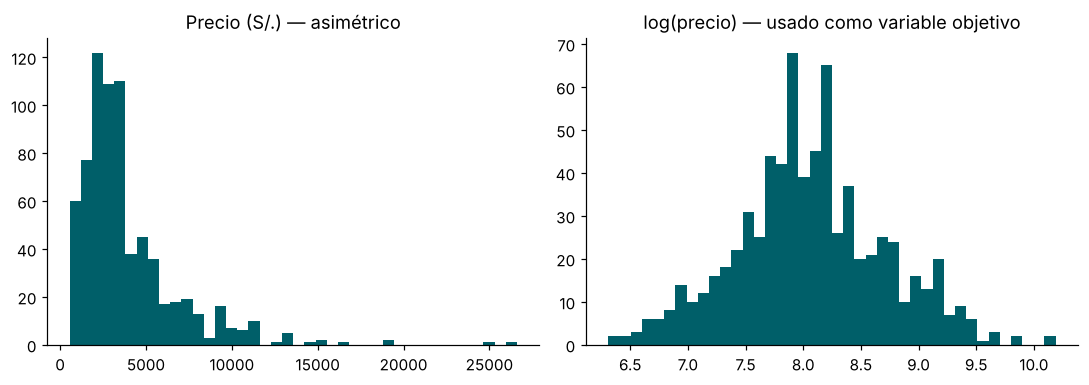

Alquileres por distrito:


district_grp,Miraflores,Otro,San Isidro,Santiago de Surco,Barranco,San Borja,San Miguel,La Molina,Surquillo,Chorrillos,Comas,Lince
anuncios,194,145,105,81,35,32,30,27,21,17,17,16


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(df['price_pen'], bins=40, color=ACENTO); ax[0].set_title('Precio (S/.) — asimétrico')
ax[1].hist(np.log(df['price_pen']), bins=40, color=ACENTO); ax[1].set_title('log(precio) — usado como variable objetivo')
plt.tight_layout(); plt.show()
print('Alquileres por distrito:'); display(df['district_grp'].value_counts().to_frame('anuncios').T)

## 2. Desempeño: MCO vs. Ridge vs. Elastic Net
Métricas sobre el conjunto de prueba (y entrenamiento) con los hiperparámetros elegidos por validación cruzada de 5 pliegues.

In [4]:
rows = []
for nombre, k in [('MCO (sin regularizar)', 'ols'), ('Ridge', 'ridge'), ('Elastic Net', 'en')]:
    for split, key in [('entrenamiento', f'm_{k}_train'), ('prueba', f'm_{k}_test')]:
        rows.append({'modelo': nombre, 'conjunto': split, **R[key]})
tabla = pd.DataFrame(rows)
display(tabla.pivot(index='modelo', columns='conjunto', values=['R2','RMSE']).round(4))
print(f"Ridge: lambda_min = {R['lam_min']:.3f} (lambda_1se = {R['lam_1se']:.3f})")
print(f"Elastic Net: alpha = {R['alpha_opt']}, lambda = {R['lam_opt']:.3f}, variables activas = {R['en_n_active']}/{R['p']}")

R2                  RMSE        
conjunto              entrenamiento  prueba entrenamiento  prueba
modelo                                                           
Elastic Net                  0.7926  0.7912        0.2926  0.3117
MCO (sin regularizar)        0.7938  0.7839        0.2917  0.3171
Ridge                        0.7934  0.7833        0.2919  0.3176

Ridge: lambda_min = 1.957 (lambda_1se = 13.335)
Elastic Net: alpha = 0.9, lambda = 0.702, variables activas = 31/34


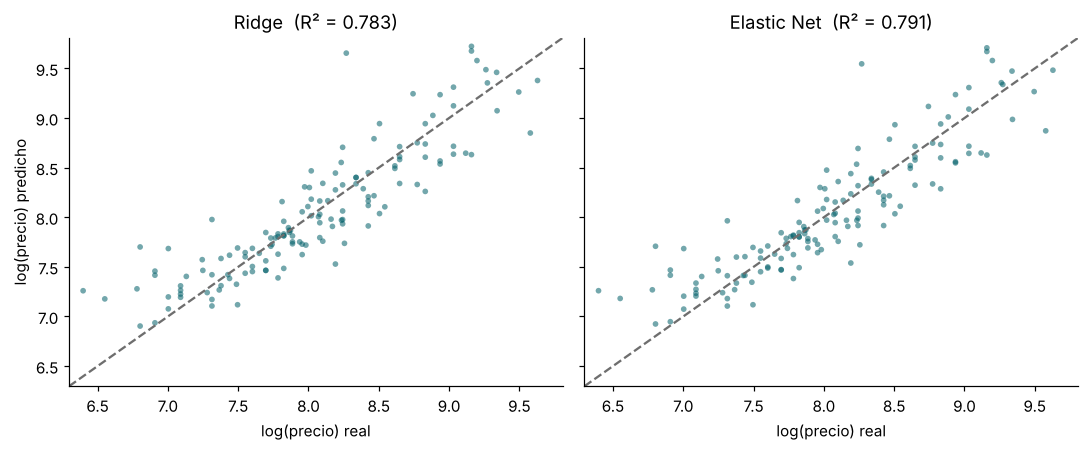

In [5]:
y_te = fit['y_test']
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
for ax, pred, nom, r2 in zip(axes, [fit['pred_te_r'], fit['pred_te_e']], ['Ridge','Elastic Net'],
                             [R['m_ridge_test']['R2'], R['m_en_test']['R2']]):
    ax.scatter(y_te, pred, s=14, alpha=.55, color=ACENTO, edgecolors='none')
    lim = [min(y_te.min(), pred.min())-.1, max(y_te.max(), pred.max())+.1]
    ax.plot(lim, lim, '--', color=GRIS); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f'{nom}  (R² = {r2:.3f})'); ax.set_xlabel('log(precio) real')
axes[0].set_ylabel('log(precio) predicho'); plt.tight_layout(); plt.show()

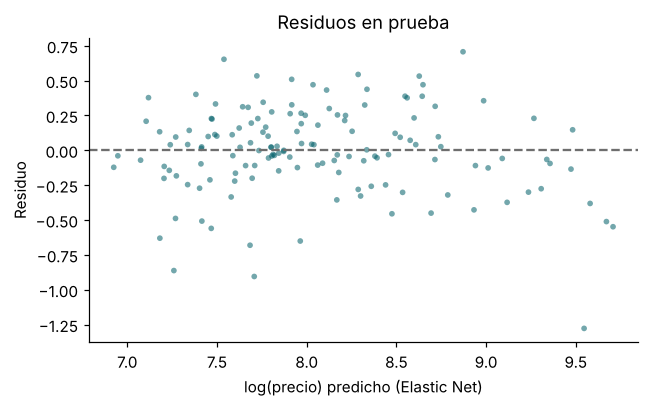

In [6]:
resid = y_te - fit['pred_te_e']
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.scatter(fit['pred_te_e'], resid, s=14, alpha=.55, color=ACENTO, edgecolors='none')
ax.axhline(0, color=GRIS, ls='--'); ax.set_xlabel('log(precio) predicho (Elastic Net)'); ax.set_ylabel('Residuo')
ax.set_title('Residuos en prueba'); plt.tight_layout(); plt.show()

## 3. Selección de hiperparámetros (validación cruzada)

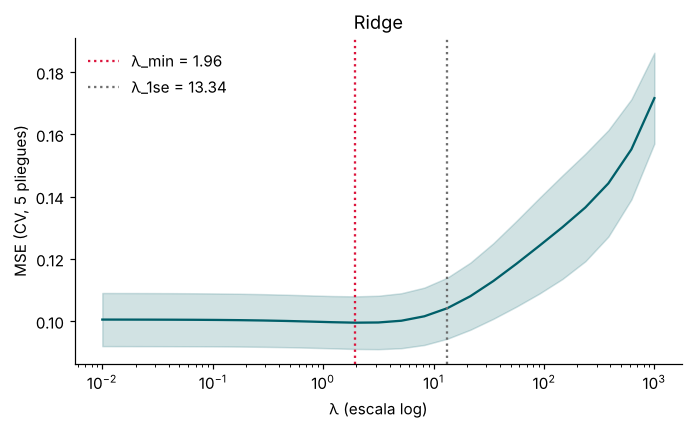

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 4))
se = cv_ridge['cv_std'] / np.sqrt(5)
ax.plot(cv_ridge['lambda'], cv_ridge['cv_mse'], color=ACENTO)
ax.fill_between(cv_ridge['lambda'], cv_ridge['cv_mse']-se, cv_ridge['cv_mse']+se, color=ACENTO, alpha=.18)
ax.axvline(R['lam_min'], color=ROJO, ls=':', label=f"λ_min = {R['lam_min']:.2f}")
ax.axvline(R['lam_1se'], color=GRIS, ls=':', label=f"λ_1se = {R['lam_1se']:.2f}")
ax.set_xscale('log'); ax.set_xlabel('λ (escala log)'); ax.set_ylabel('MSE (CV, 5 pliegues)')
ax.set_title('Ridge'); ax.legend(frameon=False); plt.tight_layout(); plt.show()

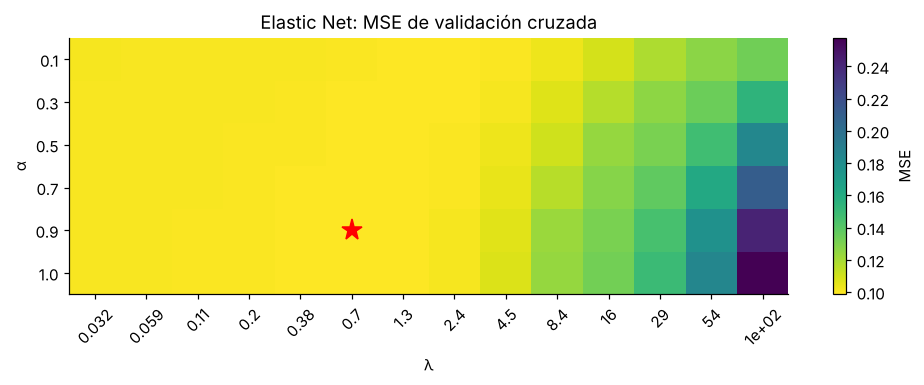

In [8]:
piv = cv_en.pivot(index='alpha', columns='lambda', values='cv_mse')
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(piv.values, aspect='auto', cmap='viridis_r')
ax.set_yticks(range(len(piv.index))); ax.set_yticklabels(piv.index)
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels([f'{c:.2g}' for c in piv.columns], rotation=45)
ax.set_xlabel('λ'); ax.set_ylabel('α'); ax.set_title('Elastic Net: MSE de validación cruzada')
i, j = np.unravel_index(np.argmin(piv.values), piv.shape)
ax.plot(j, i, 'r*', markersize=14); fig.colorbar(im, label='MSE'); plt.tight_layout(); plt.show()

## 4. Camino de regularización (Elastic Net)
Cómo se contraen —y se anulan— los coeficientes al aumentar λ.

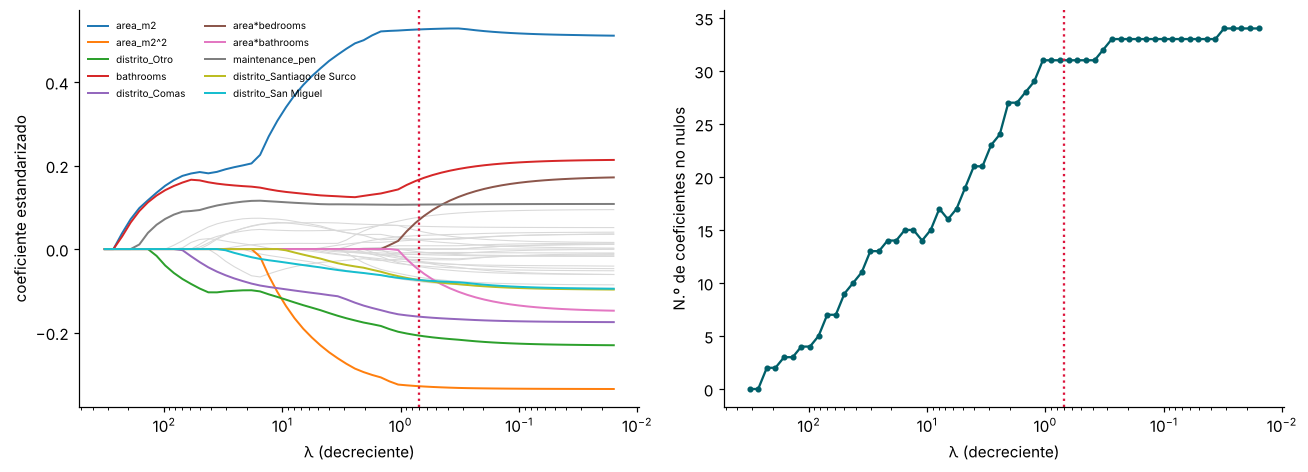

In [9]:
lam, path, nact = reg['lam_path'], reg['coef_path'], reg['n_active_path']
top = np.argsort(-np.abs(path[-1]))[:10]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for j in range(path.shape[1]):
    if j not in top: ax[0].plot(lam, path[:, j], color='0.85', lw=.7)
for k, j in enumerate(top): ax[0].plot(lam, path[:, j], lw=1.3, label=feat_names[j])
ax[0].axvline(R['lam_opt'], color=ROJO, ls=':'); ax[0].set_xscale('log'); ax[0].invert_xaxis()
ax[0].set_xlabel('λ (decreciente)'); ax[0].set_ylabel('coeficiente estandarizado'); ax[0].legend(fontsize=6.5, ncol=2, frameon=False)
ax[1].plot(lam, nact, color=ACENTO, marker='o', ms=3); ax[1].axvline(R['lam_opt'], color=ROJO, ls=':')
ax[1].set_xscale('log'); ax[1].invert_xaxis(); ax[1].set_xlabel('λ (decreciente)'); ax[1].set_ylabel('N.º de coeficientes no nulos')
plt.tight_layout(); plt.show()

## 5. Interpretación de los coeficientes
Coeficientes estandarizados de Ridge y Elastic Net (las 12 variables de mayor magnitud en Elastic Net).

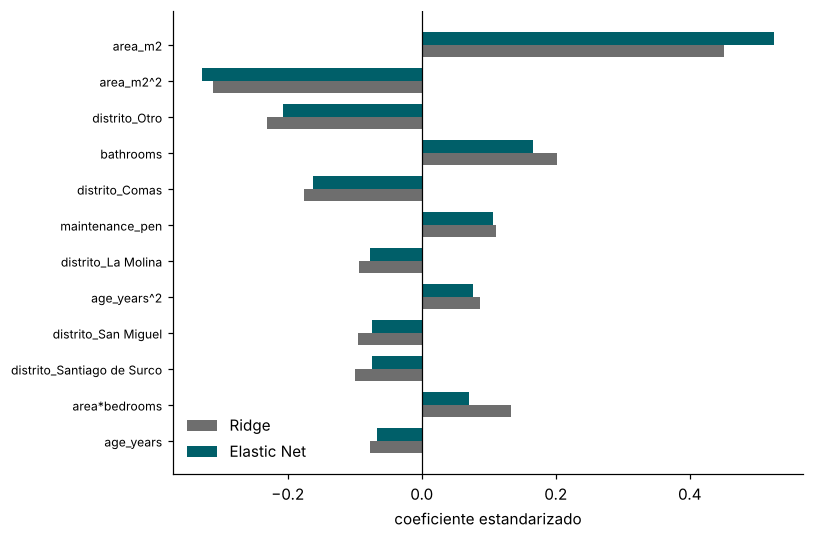

Variables que Elastic Net anuló: ['area*distrito_San Miguel', 'area*distrito_Santiago de Surco', 'area*distrito_Surquillo']


In [10]:
ridge_c, en_c = fit['ridge_coef'], fit['en_coef']
order = np.argsort(-np.abs(en_c))[:12]
y_pos = np.arange(len(order)); h = .35
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(y_pos + h/2, ridge_c[order], h, color=GRIS, label='Ridge')
ax.barh(y_pos - h/2, en_c[order], h, color=ACENTO, label='Elastic Net')
ax.set_yticks(y_pos); ax.set_yticklabels([feat_names[i] for i in order], fontsize=8); ax.invert_yaxis()
ax.axvline(0, color='k', lw=.8); ax.set_xlabel('coeficiente estandarizado'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
nulos = [str(feat_names[i]) for i in range(len(en_c)) if abs(en_c[i]) < 1e-8]
print('Variables que Elastic Net anuló:', nulos)

## 6. Verificación de las implementaciones propias
Se re-ajustan los modelos con `src/models.py` y se comparan con scikit-learn. (Se reconstruye la misma partición y estandarización de `src/03_pipeline.py`.)

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, ElasticNet

X = pd.read_csv('../data/X_full.csv').values
y = pd.read_csv('../data/y.csv')['log_price'].values
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1.0
Xtr_s, Xte_s = (Xtr-mu)/sd, (Xte-mu)/sd

mine_r = RidgeScratch(lam=R['lam_min']).fit(Xtr_s, ytr)
sk_r   = Ridge(alpha=R['lam_min']).fit(Xtr_s, ytr)
mine_e = ElasticNetScratch(lam=R['lam_opt'], alpha=R['alpha_opt'], tol=1e-8, max_iter=8000).fit(Xtr_s, ytr)
sk_e   = ElasticNet(alpha=R['lam_opt']/len(ytr), l1_ratio=R['alpha_opt'], tol=1e-10, max_iter=200000).fit(Xtr_s, ytr)

comp = pd.DataFrame({
    'Ridge (cerrada) vs sklearn':      [np.max(np.abs(mine_r.coef_ - sk_r.coef_))],
    'Ridge (GD) vs cerrada':           [GD['diff_gd_closed']],
    'Elastic Net (coord.) vs sklearn': [np.max(np.abs(mine_e.coef_ - sk_e.coef_))],
}, index=['diferencia máxima de coeficiente']).T
display(comp.map(lambda v: f'{v:.2e}'))

,diferencia máxima de coeficiente
Ridge (cerrada) vs sklearn,5.88e-15
Ridge (GD) vs cerrada,4.74e-08
Elastic Net (coord.) vs sklearn,5.64e-07


Ridge por descenso del gradiente sobre el dataset real:
  L = 3605.3   μ = 3.95   κ = L/μ ≈ 913   η = 1/L = 2.77e-04
  convergió en 12,304 iteraciones (tol = 1e-10)


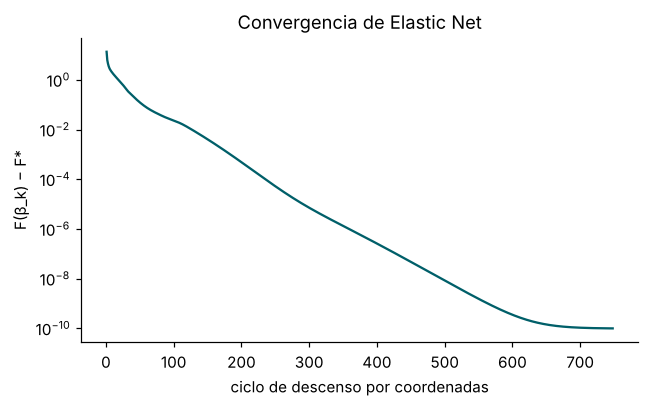

In [12]:
print(f"Ridge por descenso del gradiente sobre el dataset real:")
print(f"  L = {GD['L']:.1f}   μ = {GD['mu']:.2f}   κ = L/μ ≈ {GD['kappa']:.0f}   η = 1/L = {GD['eta']:.2e}")
print(f"  convergió en {GD['n_iter_gd']:,} iteraciones (tol = 1e-10)")
loss = fit['en_loss_path']
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(np.arange(1, len(loss)+1), loss - loss.min() + 1e-10, color=ACENTO)
ax.set_yscale('log'); ax.set_xlabel('ciclo de descenso por coordenadas'); ax.set_ylabel('F(β_k) − F*')
ax.set_title('Convergencia de Elastic Net'); plt.tight_layout(); plt.show()

## Conclusiones rápidas
* Elastic Net obtiene el mejor R² en prueba y conserva 31 de 34 variables, descartando las interacciones redundantes.
* Las tres implementaciones desde cero (Ridge cerrada, Ridge por gradiente, Elastic Net por coordenadas) coinciden con scikit-learn con diferencias despreciables.
* Para reproducir todo desde cero: `pip install numpy pandas scikit-learn matplotlib` y ejecutar `src/01_clean.py` … `src/05_gd_check.py` (en ese orden, desde la carpeta `src/`).